# Forward-Facing Sonar and Tournament Outcomes in the Bassmaster Elite Series (2012–2026)

## INSY 7130 Final Project

### Author
Joshua Etherton

# 1. Introduction
### Research Question

Forward-Facing Sonar (FFS) has fundamentally changed competitive bass fishing by allowing anglers to locate and target fish in real time. This project investigates whether tournament-level outcomes differ across periods and tournaments in which FFS was unavailable, unrestricted, restricted, or prohibited.

Specifically, I evaluate associations between FFS availability and:

- Total catch weight
- Number of fish caught
- Average fish weight

I also investigate whether these relationships vary among fisheries (waterbodies) and over time.

# 2. Data Description

The dataset contains Bassmaster Elite Series tournament results from approximately 2012–2026.

Each observation represents a single angler's performance in a tournament.

Key variables include:

- Season_Year
- Tournament_ID
- Event_Name
- Location
- Waterbody
- Allowed_FFS
- Place
- Angler_Name
- Fish_Caught
- Weight_Lbs_Calculated
- Fantasy_Points

Derived Variable:

Average Fish Weight

\[
\text{Avg Fish Weight} =
\frac{\text{Weight (lbs)}}{\text{Fish Caught}}
\]

In [15]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# df = pd.read_csv("bass_cleaned.csv")
df = pd.read_csv("bass_final_cleaned.csv")

df.head()

,Season_Year,Tournament_ID,Event_Name,Allowed_FFS,Metadata_Source,Place,Angler_Name,Player_ID,Fish_Caught,Weight_Oz,Big_Bag_Points,Big_Bass_Points,Leader_Bonus,Fantasy_Points,Source_URL,Weight_Lbs_Calculated,Weight_Lbs,Weight_Oz_Remainder,Potential_Duplicate,Metadata_Needs_Review,Avg_Fish_Weight,Month,Waterbody,Tournament_Dates,Location,Row_ID
0,2012,1,Bassmaster Classic,No FFS Existed,supplied_inventory_title_match,1,Chris Lane,168,15,822,40.0,NaN,10.0,350,https://bassmasterfantasy.com/TournamentDetail...,51.3750,51.0,6.0,False,True,3.425000,Feb,Red River,"Feb 24–26, 2012","Shreveport, LA",1
1,2012,1,Bassmaster Classic,No FFS Existed,supplied_inventory_title_match,2,Greg Vinson,213,15,767,NaN,NaN,5.0,295,https://bassmasterfantasy.com/TournamentDetail...,47.9375,47.0,15.0,False,True,3.195833,Feb,Red River,"Feb 24–26, 2012","Shreveport, LA",1
2,2012,1,Bassmaster Classic,No FFS Existed,supplied_inventory_title_match,3,Keith Poche,186,15,735,NaN,40.0,10.0,335,https://bassmasterfantasy.com/TournamentDetail...,45.9375,45.0,15.0,False,True,3.062500,Feb,Red River,"Feb 24–26, 2012","Shreveport, LA",1
3,2012,1,Bassmaster Classic,No FFS Existed,supplied_inventory_title_match,4,Alton Jones,130,15,734,NaN,NaN,5.0,285,https://bassmasterfantasy.com/TournamentDetail...,45.8750,45.0,14.0,False,True,3.058333,Feb,Red River,"Feb 24–26, 2012","Shreveport, LA",1
4,2012,1,Bassmaster Classic,No FFS Existed,supplied_inventory_title_match,5,Ott Defoe,149,15,718,NaN,NaN,10.0,280,https://bassmasterfantasy.com/TournamentDetail...,44.8750,44.0,14.0,False,True,2.991667,Feb,Red River,"Feb 24–26, 2012","Shreveport, LA",1


In [19]:
print(df.shape)

df.info()

(13968, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13968 entries, 0 to 13967
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Season_Year            13968 non-null  int64  
 1   Tournament_ID          13968 non-null  int64  
 2   Event_Name             13968 non-null  object 
 3   Allowed_FFS            13968 non-null  object 
 4   Metadata_Source        13968 non-null  object 
 5   Place                  13968 non-null  int64  
 6   Angler_Name            13968 non-null  object 
 7   Player_ID              13968 non-null  int64  
 8   Fish_Caught            13968 non-null  int64  
 9   Weight_Oz              13968 non-null  int64  
 10  Big_Bag_Points         153 non-null    float64
 11  Big_Bass_Points        164 non-null    float64
 12  Leader_Bonus           1375 non-null   float64
 13  Fantasy_Points         13968 non-null  int64  
 14  Source_URL             13968 non-null  obj

In [20]:
df.describe(include="all")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Season_Year,Tournament_ID,Event_Name,Allowed_FFS,Metadata_Source,Place,Angler_Name,Player_ID,Fish_Caught,Weight_Oz,Big_Bag_Points,Big_Bass_Points,Leader_Bonus,Fantasy_Points,Source_URL,Weight_Lbs_Calculated,Weight_Lbs,Weight_Oz_Remainder,Potential_Duplicate,Metadata_Needs_Review,Avg_Fish_Weight,Month,Waterbody,Tournament_Dates,Location,Row_ID
count,13968.000000,13968.000000,13968,13968,13968,13968.000000,13968,13968.000000,13968.000000,13968.000000,153.0,164.0,1375.000000,13968.000000,13968,13968.000000,13967.000000,13967.000000,13968,13968,1.393000e+04,12358,13968,13968,13968,13968.000000
unique,NaN,NaN,3,6,3,NaN,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN,150,NaN,NaN,NaN,1,1,NaN,9,62,145,77,NaN
top,NaN,NaN,Elite Series,Yes (Unrestricted),supplied_inventory_title_match,NaN,Bill Lowen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://bassmasterfantasy.com/TournamentDetail...,NaN,NaN,NaN,False,True,NaN,Apr,St. Lawrence River,"Feb 9–12, 2017","Palatka, FL",NaN
freq,NaN,NaN,12963,8349,11681,NaN,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN,113,NaN,NaN,NaN,13968,13968,NaN,2294,983,220,792,NaN
mean,2019.080756,5.546392,NaN,NaN,NaN,48.855813,NaN,290.079611,11.801332,555.354310,40.0,40.0,5.858182,179.932847,NaN,34.709644,34.246152,7.456791,NaN,NaN,-inf,NaN,NaN,NaN,NaN,74.918743
std,4.300159,2.824170,NaN,NaN,NaN,29.303044,NaN,114.104682,4.232416,300.236147,0.0,0.0,2.395919,63.652558,NaN,18.764759,18.765513,4.626983,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.476499
min,2012.000000,1.000000,NaN,NaN,NaN,1.000000,NaN,117.000000,0.000000,-16.000000,40.0,40.0,5.000000,0.000000,NaN,-1.000000,0.000000,0.000000,NaN,NaN,-inf,NaN,NaN,NaN,NaN,1.000000
25%,2015.000000,3.000000,NaN,NaN,NaN,24.000000,NaN,181.000000,10.000000,334.000000,40.0,40.0,5.000000,129.000000,NaN,20.875000,20.000000,3.000000,NaN,NaN,2.283333e+00,NaN,NaN,NaN,NaN,37.000000
50%,2019.000000,6.000000,NaN,NaN,NaN,47.000000,NaN,289.000000,10.000000,500.000000,40.0,40.0,5.000000,181.000000,NaN,31.250000,31.000000,7.000000,NaN,NaN,2.756250e+00,NaN,NaN,NaN,NaN,73.000000
75%,2023.000000,8.000000,NaN,NaN,NaN,73.000000,NaN,394.000000,15.000000,732.000000,40.0,40.0,5.000000,227.000000,NaN,45.750000,45.000000,11.000000,NaN,NaN,3.320703e+00,NaN,NaN,NaN,NaN,114.000000


# 3. Data Preparation

Several tournament locations were standardized into common fisheries (Waterbody).

Examples include:

- Lake Guntersville
- St. Lawrence River
- Lake Okeechobee
- Oneida Lake
- Toledo Bend Reservoir

This standardization allows repeated observations from the same fishery to be analyzed consistently through time.

In [21]:
df.isna().sum().sort_values(ascending=False)

Big_Bag_Points           13815
Big_Bass_Points          13804
Leader_Bonus             12593
Month                     1610
Avg_Fish_Weight             38
Weight_Oz_Remainder          1
Weight_Lbs                   1
Season_Year                  0
Weight_Lbs_Calculated        0
Location                     0
Tournament_Dates             0
Waterbody                    0
Metadata_Needs_Review        0
Potential_Duplicate          0
Fantasy_Points               0
Source_URL                   0
Tournament_ID                0
Weight_Oz                    0
Fish_Caught                  0
Player_ID                    0
Angler_Name                  0
Place                        0
Metadata_Source              0
Allowed_FFS                  0
Event_Name                   0
Row_ID                       0
dtype: int64

In [22]:
df["Avg_Fish_Weight"] = (
    df["Weight_Lbs_Calculated"] /
    df["Fish_Caught"]
)

df["Avg_Fish_Weight"] = (
    df["Avg_Fish_Weight"]
    .replace([np.inf, -np.inf], np.nan)
)

# 4. Exploratory Data Analysis

Before investigating the effects of Forward-Facing Sonar (FFS), the dataset was explored to understand its overall structure, identify potential data quality issues, and examine distributions of key response variables.

Particular attention was given to:

- Tournament representation through time
- Fishery representation
- Fish catch distributions
- Tournament weight distributions
- Average fish weight distributions

These exploratory analyses provide context for subsequent sections and help identify factors that may require additional investigation.

### Tournament Representation Through Time
Because the dataset spans approximately 2012–2026, it is important to understand how many tournaments are represented in each season.

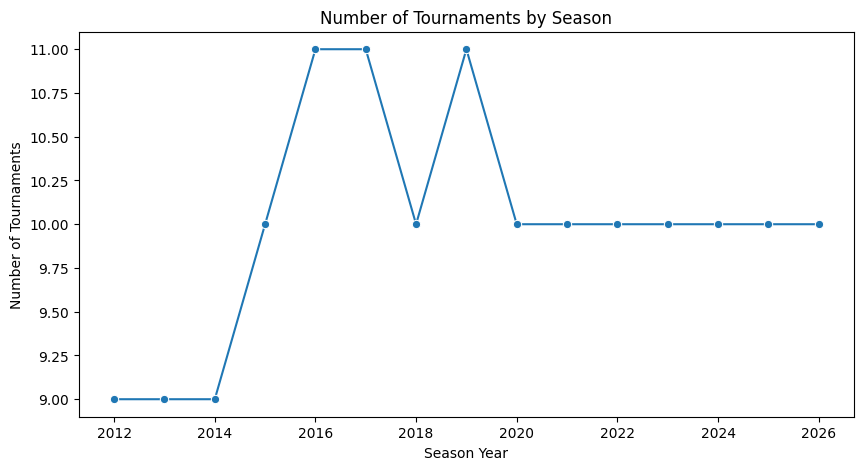

In [23]:
tournaments_per_year = (
    df.groupby("Season_Year")["Tournament_ID"]
      .nunique()
      .reset_index()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    data=tournaments_per_year,
    x="Season_Year",
    y="Tournament_ID",
    marker="o"
)

plt.title("Number of Tournaments by Season")
plt.xlabel("Season Year")
plt.ylabel("Number of Tournaments")

plt.show()

### Fishery Representation

Some fisheries appear repeatedly throughout the dataset while others were only visited once or twice.

Understanding this distribution helps identify fisheries with sufficient observations for later trend analyses.

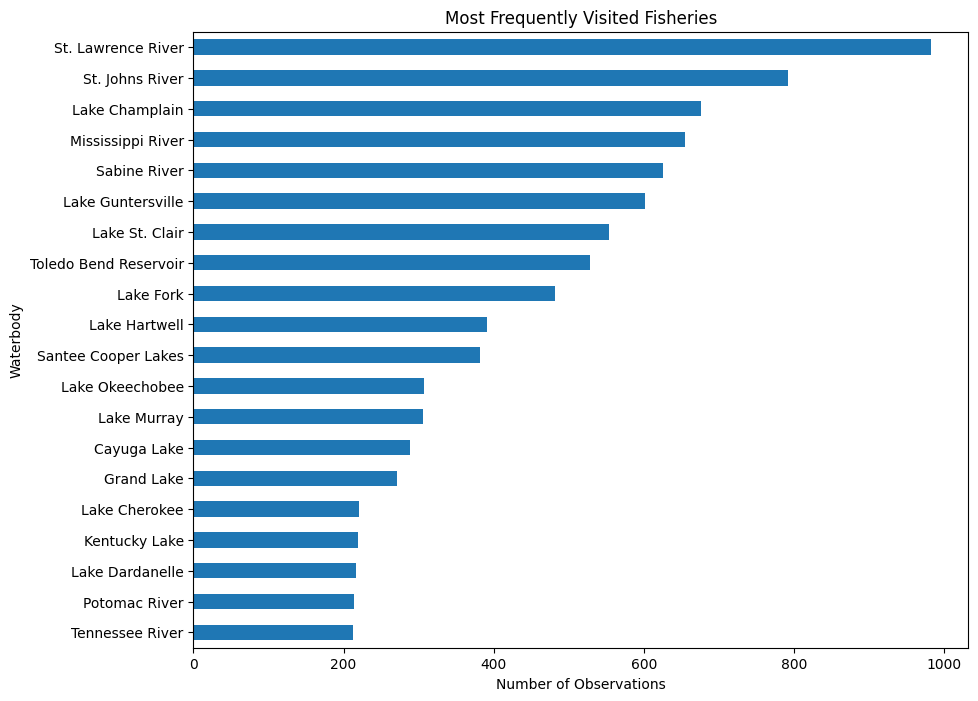

In [24]:
plt.figure(figsize=(10,8))

(
    df["Waterbody"]
      .value_counts()
      .head(20)
      .sort_values()
      .plot(kind="barh")
)

plt.title("Most Frequently Visited Fisheries")
plt.xlabel("Number of Observations")
plt.ylabel("Waterbody")

plt.show()

### Distribution of Fish Caught

The distribution of fish caught provides an initial look at tournament performance and catch success across all events in the dataset.

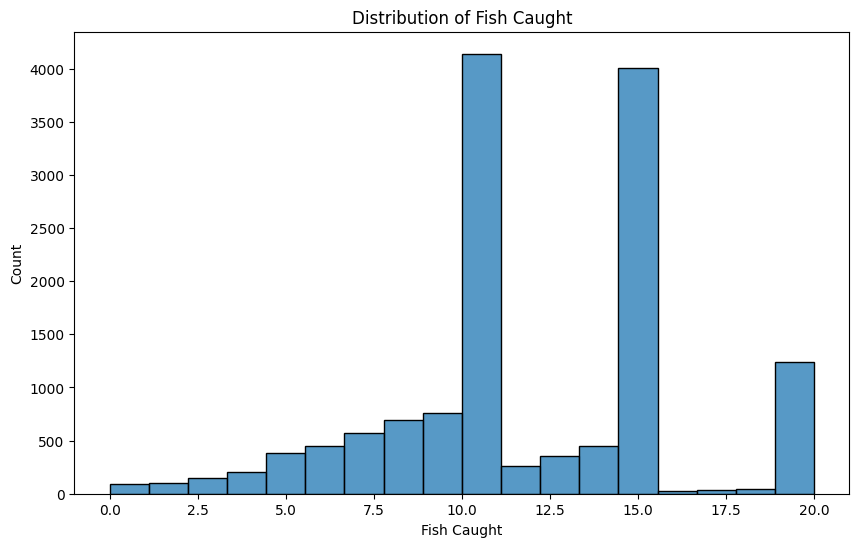

In [25]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Fish_Caught",
    bins=18
)

plt.title("Distribution of Fish Caught")
plt.xlabel("Fish Caught")
plt.ylabel("Count")

plt.show()

Several prominent peaks are visible throughout the distribution rather than a smooth continuous pattern.

These recurring peaks suggest that factors beyond fish abundance or angler performance may influence the reported number of fish caught. Additional investigation is warranted.

### Distribution of Tournament Weight

Tournament weight represents one of the primary performance metrics in bass fishing competitions.

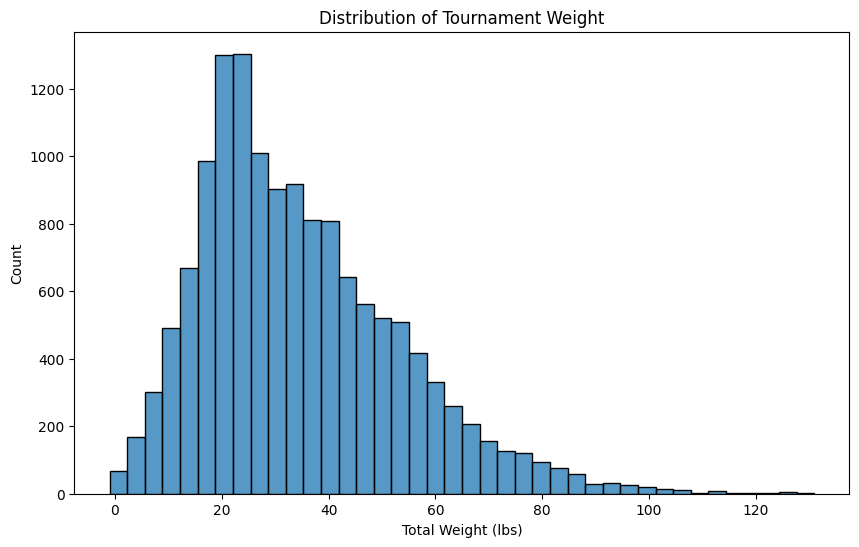

In [26]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Weight_Lbs_Calculated",
    bins=40
)

plt.title("Distribution of Tournament Weight")
plt.xlabel("Total Weight (lbs)")
plt.ylabel("Count")

plt.show()

Tournament weights exhibit a right-skewed distribution, with most observations concentrated within a relatively narrow range and fewer observations occurring at extremely high weights.

### Distribution of Average Fish Weight

Average fish weight was calculated as total tournament weight divided by the number of fish caught.

This variable provides a measure of fish size independent of total catch count.

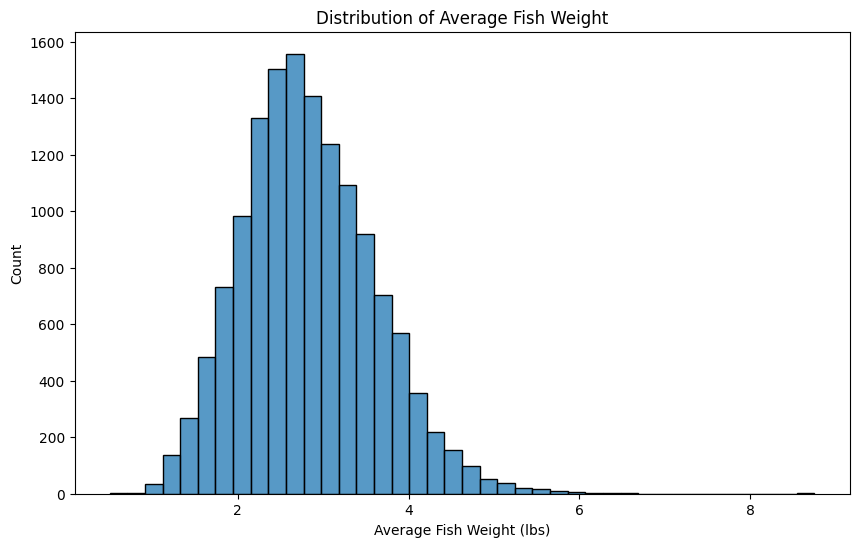

In [27]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Avg_Fish_Weight",
    bins=40
)

plt.title("Distribution of Average Fish Weight")
plt.xlabel("Average Fish Weight (lbs)")
plt.ylabel("Count")

plt.show()

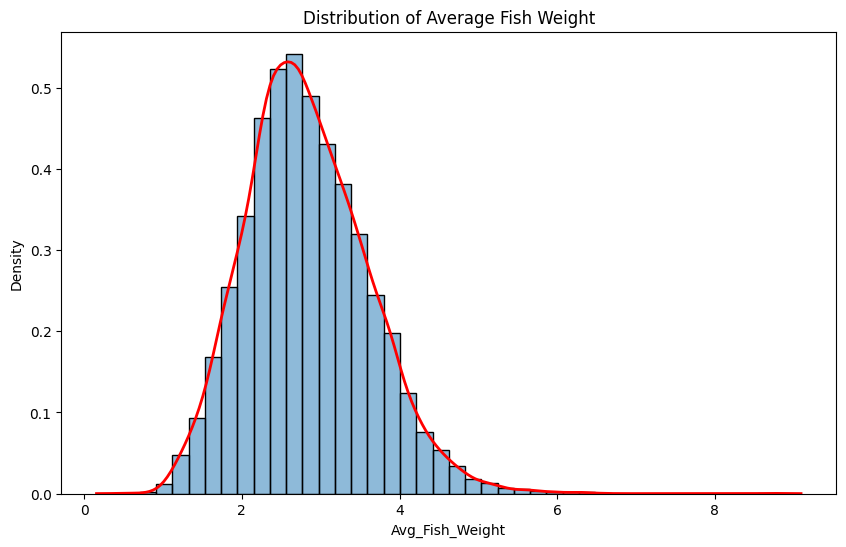

In [28]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Avg_Fish_Weight"],
    bins=40,
    stat="density",
    alpha=0.5
)

sns.kdeplot(
    df["Avg_Fish_Weight"],
    color="red",
    linewidth=2
)

plt.title("Distribution of Average Fish Weight")

plt.show()

### Distribution of FFS Categories

Before evaluating tournament outcomes, the relative representation of each FFS category was examined.

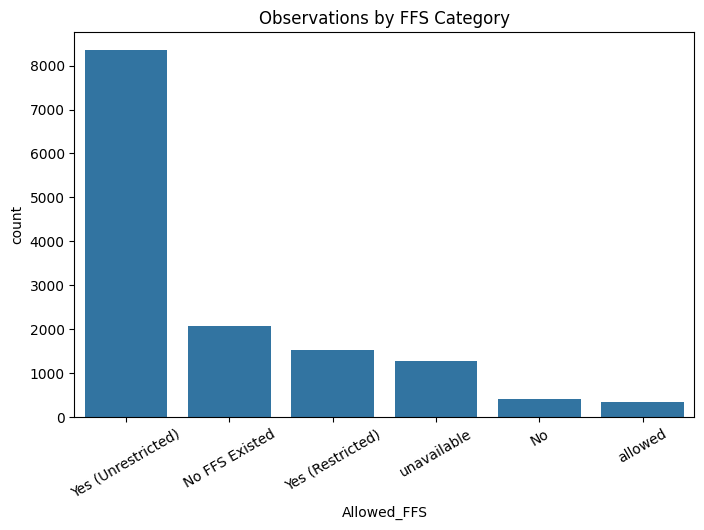

In [29]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Allowed_FFS",
    order=df["Allowed_FFS"].value_counts().index
)

plt.title("Observations by FFS Category")

plt.xticks(rotation=30)

plt.show()

### Initial Observations

Several patterns emerged during exploratory analysis:

1. Tournament weights and average fish weights appear broadly continuous and suitable for quantitative analysis.

2. Fish catch counts exhibit unusually strong peaks at specific values rather than a smooth distribution.

3. These peaks suggest that tournament rules or event structure may influence recorded catch counts.

Because these patterns could affect all subsequent analyses, the next section investigates tournament structure in greater detail.

# 5. Tournament Structure Effects

Initial exploratory analysis revealed strong evidence that tournament structure influences tournament outcomes.

Bassmaster Elite tournaments are typically conducted using a five-fish daily limit across multiple competition days. Consequently, tournaments of different durations produce different maximum allowable catches.

This has important implications:

- Raw fish counts are constrained by tournament duration.
- Average fish weight may increase in shorter tournaments because anglers can selectively retain larger fish.
- Comparisons among tournaments must account for differences in bag limits.

Before evaluating FFS effects, tournament structure must be examined as a potential source of variation.

In [32]:
# Extract the numeric portion of Place and convert it to a number
df["Place_Numeric"] = pd.to_numeric(
    df["Place"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

df[["Place", "Place_Numeric"]].head()

,Place,Place_Numeric
0,1,1
1,2,2
2,3,3
3,4,4
4,5,5


In [33]:
# One winner record for each unique tournament event
winners = (
    df.loc[df["Place_Numeric"] == 1,
           ["Season_Year", "Tournament_ID", "Event_Name",
            "Waterbody", "Fish_Caught"]]
      .drop_duplicates(
          subset=["Season_Year", "Tournament_ID"]
      )
      .rename(
          columns={"Fish_Caught": "Winner_Fish_Caught"}
      )
)

winners.head()

,Season_Year,Tournament_ID,Event_Name,Waterbody,Winner_Fish_Caught
0,2012,1,Bassmaster Classic,Red River,15
49,2012,2,Elite Series,St. Johns River,20
148,2012,3,Elite Series,Lake Okeechobee,20
247,2012,4,Elite Series,Bull Shoals Lake,20
346,2012,5,Elite Series,Douglas Lake,20


In [34]:
def infer_bag_limit(winner_fish_count):
    """
    Round the winner's fish count upward to the next possible
    cumulative tournament bag limit: 5, 10, 15, or 20.
    """
    
    if pd.isna(winner_fish_count):
        return np.nan
    elif winner_fish_count <= 5:
        return 5
    elif winner_fish_count <= 10:
        return 10
    elif winner_fish_count <= 15:
        return 15
    elif winner_fish_count <= 20:
        return 20
    else:
        # Values above 20 require manual review
        return np.nan


winners["Bag_Limit"] = (
    winners["Winner_Fish_Caught"]
    .apply(infer_bag_limit)
)

In [35]:
winners[
    [
        "Season_Year",
        "Tournament_ID",
        "Event_Name",
        "Waterbody",
        "Winner_Fish_Caught",
        "Bag_Limit"
    ]
].sort_values(
    ["Season_Year", "Tournament_ID"]
).head(20)

,Season_Year,Tournament_ID,Event_Name,Waterbody,Winner_Fish_Caught,Bag_Limit
0,2012,1,Bassmaster Classic,Red River,15,15
49,2012,2,Elite Series,St. Johns River,20,20
148,2012,3,Elite Series,Lake Okeechobee,20,20
247,2012,4,Elite Series,Bull Shoals Lake,20,20
346,2012,5,Elite Series,Douglas Lake,20,20
445,2012,6,Elite Series,Toledo Bend Reservoir,20,20
544,2012,7,Elite Series,Mississippi River,20,20
642,2012,8,Elite Series,Green Bay,20,20
740,2012,9,Elite Series,Oneida Lake,20,20
837,2013,1,Bassmaster Classic,Grand Lake,14,15


In [36]:
# Remove an existing Bag_Limit column if this cell was previously run
df = df.drop(
    columns=["Bag_Limit"],
    errors="ignore"
)

df = df.merge(
    winners[
        [
            "Season_Year",
            "Tournament_ID",
            "Bag_Limit"
        ]
    ],
    on=["Season_Year", "Tournament_ID"],
    how="left",
    validate="many_to_one"
)

In [37]:
bag_summary = (
    df.groupby("Bag_Limit")
      .agg({
          "Fish_Caught":["mean","median"],
          "Weight_Lbs_Calculated":["mean","median"],
          "Avg_Fish_Weight":["mean","median"]
      })
)

bag_summary

Fish_Caught        Weight_Lbs_Calculated           Avg_Fish_Weight  \
                 mean median                  mean    median            mean   
Bag_Limit                                                                      
10           8.940000   10.0             32.166250  34.34375        3.579292   
15          10.859189   11.0             32.731205  30.81250        2.920350   
20          11.906169   10.0             34.916110  31.25000        2.811224   

                     
             median  
Bag_Limit            
10         3.597321  
15         2.868750  
20         2.742188

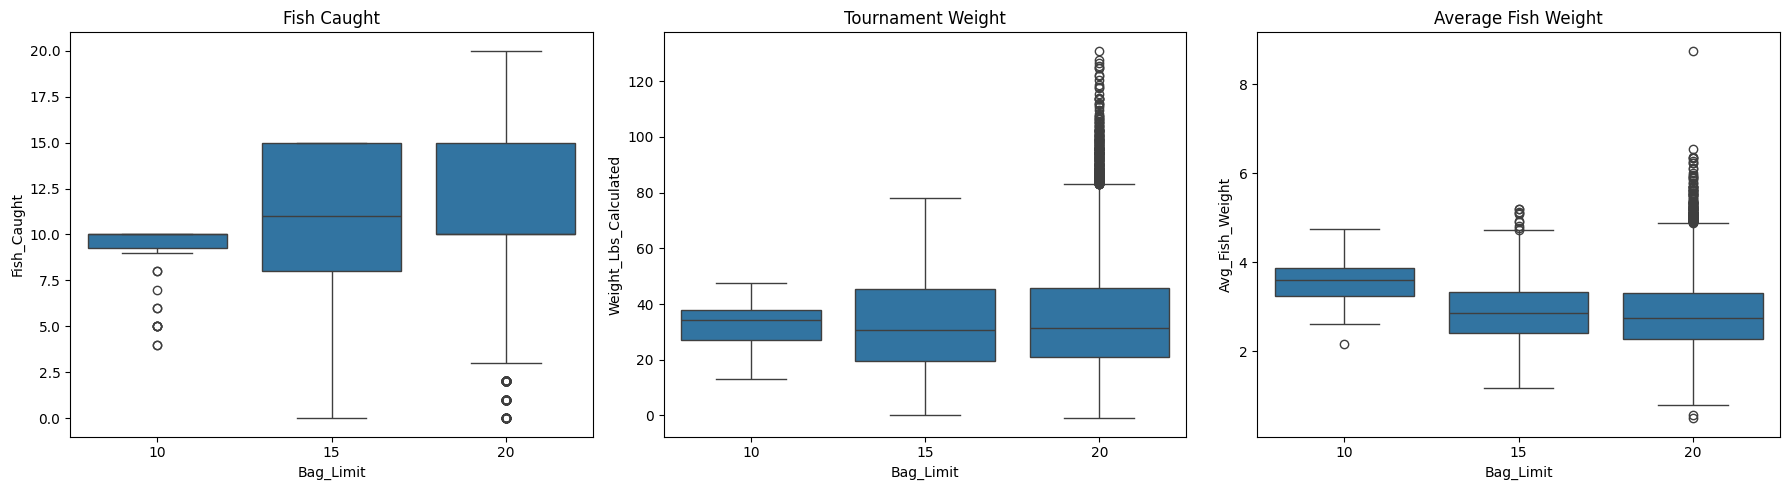

In [38]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18,5)
)

sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Fish_Caught",
    ax=axes[0]
)

sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Weight_Lbs_Calculated",
    ax=axes[1]
)

sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Avg_Fish_Weight",
    ax=axes[2]
)

axes[0].set_title("Fish Caught")
axes[1].set_title("Tournament Weight")
axes[2].set_title("Average Fish Weight")

plt.tight_layout()
plt.show()

### 1. Make sure finishing place is numeric

In [44]:
df["Place_Numeric"] = pd.to_numeric(
    df["Place"]
      .astype(str)
      .str.extract(r"(\d+)")[0],
    errors="coerce"
)

### 2. Infer days competed

In [45]:
def infer_days_competed(row):
    """
    Infer the number of competition days available to an angler
    based on the event's total bag limit and the angler's finish.

    Assumptions:
    - Five-fish daily limit
    - Full field fishes Days 1 and 2
    - Top 50 advances to Day 3
    - Top 10 advances to Day 4
    """
    
    event_limit = row["Bag_Limit"]
    place = row["Place_Numeric"]

    if pd.isna(event_limit) or pd.isna(place):
        return np.nan

    # Two-day event: all participating anglers could fish two days
    if event_limit == 10:
        return 2

    # Three-day event: full field fishes two days;
    # top 50 receives a third day
    elif event_limit == 15:
        if place <= 50:
            return 3
        else:
            return 2

    # Four-day event: full field fishes two days;
    # top 50 receives Day 3 and top 10 receives Day 4
    elif event_limit == 20:
        if place <= 10:
            return 4
        elif place <= 50:
            return 3
        else:
            return 2

    return np.nan


df["Days_Competed_Est"] = df.apply(
    infer_days_competed,
    axis=1
)

### 3. Calculate the angler-specific eligible bag limit

In [46]:
df["Eligible_Bag_Limit"] = (
    df["Days_Competed_Est"] * 5
)

### 4. Calculate the adjusted proportion of eligible limit

In [47]:
df["Pct_Eligible_Limit"] = (
    df["Fish_Caught"] /
    df["Eligible_Bag_Limit"]
)

df["Pct_Eligible_Limit_100"] = (
    df["Pct_Eligible_Limit"] * 100
)

In [48]:
(
    df.groupby(
        [
            "Bag_Limit",
            "Days_Competed_Est",
            "Eligible_Bag_Limit"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Observations")
    .sort_values(
        ["Bag_Limit", "Days_Competed_Est"]
    )
)

invalid_eligible_limits = df.loc[
    df["Fish_Caught"] > df["Eligible_Bag_Limit"],
    [
        "Season_Year",
        "Tournament_ID",
        "Event_Name",
        "Place",
        "Place_Numeric",
        "Fish_Caught",
        "Bag_Limit",
        "Days_Competed_Est",
        "Eligible_Bag_Limit"
    ]
]

print(
    "Rows exceeding estimated eligible limit:",
    len(invalid_eligible_limits)
)

invalid_eligible_limits.head(20)

Rows exceeding estimated eligible limit: 120


,Season_Year,Tournament_ID,Event_Name,Place,Place_Numeric,Fish_Caught,Bag_Limit,Days_Competed_Est,Eligible_Bag_Limit
59,2012,2,Elite Series,11,11,20,20,3,15
60,2012,2,Elite Series,12,12,20,20,3,15
158,2012,3,Elite Series,11,11,20,20,3,15
159,2012,3,Elite Series,12,12,19,20,3,15
257,2012,4,Elite Series,11,11,20,20,3,15
258,2012,4,Elite Series,12,12,20,20,3,15
356,2012,5,Elite Series,11,11,20,20,3,15
357,2012,5,Elite Series,12,12,20,20,3,15
455,2012,6,Elite Series,11,11,17,20,3,15
456,2012,6,Elite Series,12,12,18,20,3,15


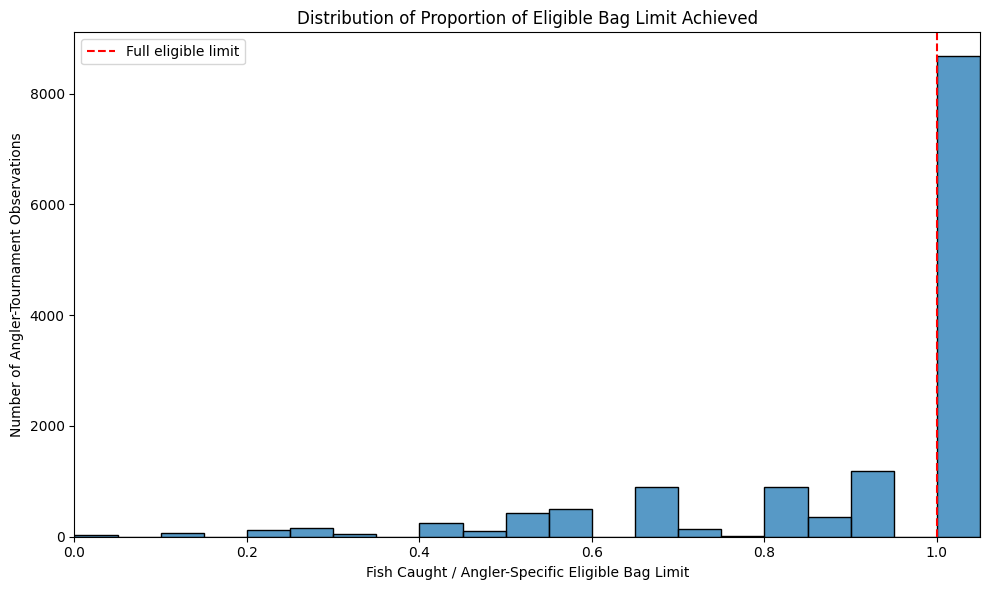

In [57]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Pct_Eligible_Limit",
    bins=np.arange(0, 1.1, 0.05),
    edgecolor="black",
    # bins=10
)

plt.axvline(
    1.0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Full eligible limit"
)

plt.title(
    "Distribution of Proportion of Eligible Bag Limit Achieved"
)

plt.xlabel(
    "Fish Caught / Angler-Specific Eligible Bag Limit"
)

plt.ylabel("Number of Angler-Tournament Observations")

plt.xlim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### Initial Findings

Average fish weight varies substantially among tournament formats.

Although total catch weight remains relatively similar across bag limits, shorter tournaments tend to produce larger average fish weights. This pattern is consistent with increased opportunities for culling and high-grading catches.

These results suggest that tournament format is a potential confounding variable that should be included in subsequent analyses.

# 6. Standardizing Catch Success

Raw fish counts are difficult to compare across tournament formats because anglers in longer tournaments can accumulate more fish.

To allow comparisons among events, a standardized metric was created:

Percent of Limit Achieved

Fish Caught / Tournament Bag Limit

This metric places all tournaments on a common scale.

In [58]:
df["Pct_Limit"] = (
    df["Fish_Caught"] /
    df["Bag_Limit"]
)

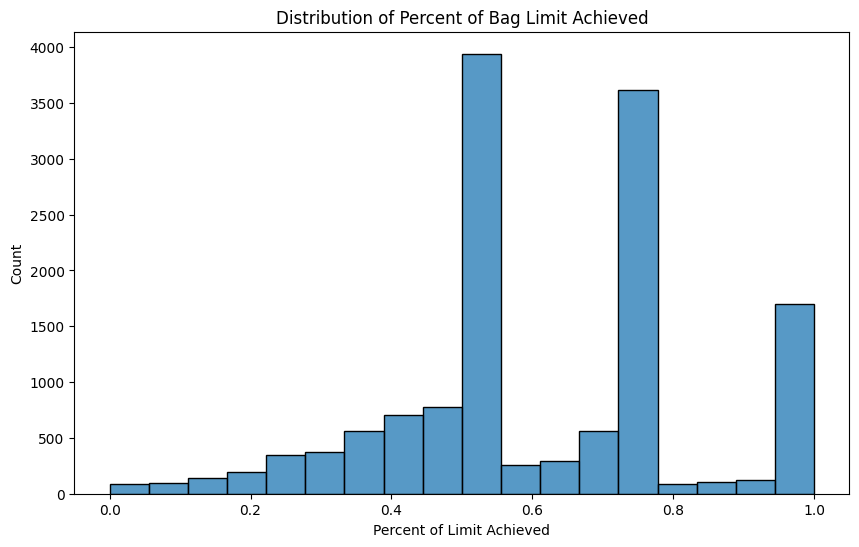

In [59]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Pct_Limit"],
    bins=18
)

plt.title("Distribution of Percent of Bag Limit Achieved")
plt.xlabel("Percent of Limit Achieved")
plt.ylabel("Count")

plt.show()


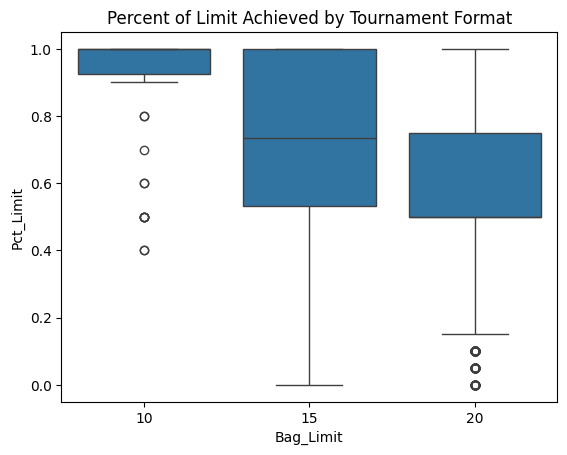

In [60]:
sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Pct_Limit"
)

plt.title("Percent of Limit Achieved by Tournament Format")

plt.show()

Percent of limit achieved provides a more meaningful measure of catch success than raw fish counts because it adjusts for differences in tournament duration.

# 7. Temporal Trends

Forward-facing sonar emerged during the late 2010s and rapidly spread throughout professional bass fishing.

This section examines whether tournament outcomes changed over time.

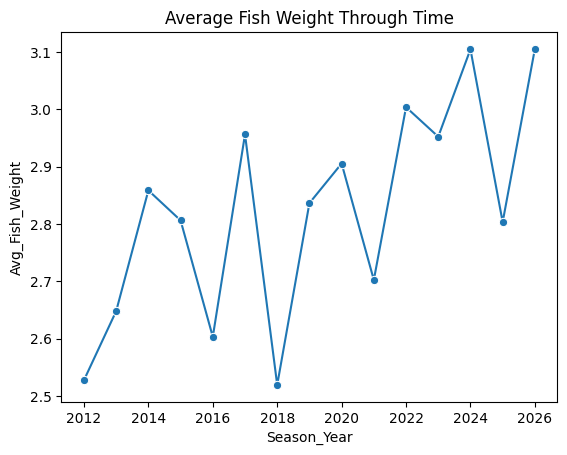

In [61]:
annual_size = (
    df.groupby("Season_Year")
      ["Avg_Fish_Weight"]
      .mean()
      .reset_index()
)

sns.lineplot(
    data=annual_size,
    x="Season_Year",
    y="Avg_Fish_Weight",
    marker="o"
)

plt.title("Average Fish Weight Through Time")

plt.show()

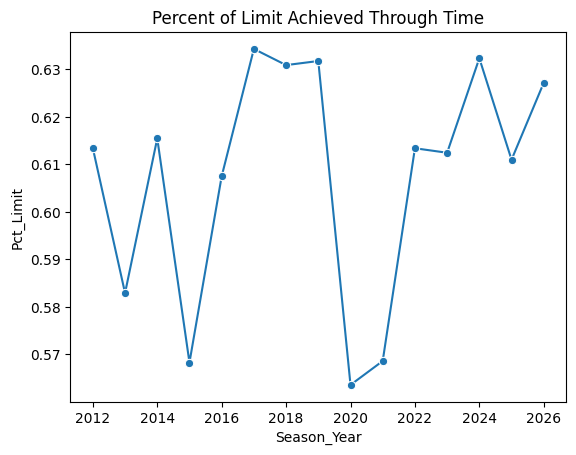

In [62]:
annual_limit = (
    df.groupby("Season_Year")
      ["Pct_Limit"]
      .mean()
      .reset_index()
)

sns.lineplot(
    data=annual_limit,
    x="Season_Year",
    y="Pct_Limit",
    marker="o"
)

plt.title("Percent of Limit Achieved Through Time")

plt.show()

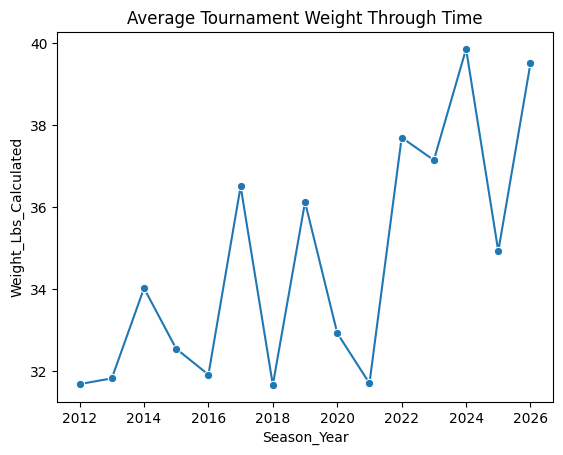

In [63]:
annual_weight = (
    df.groupby("Season_Year")
      ["Weight_Lbs_Calculated"]
      .mean()
      .reset_index()
)

sns.lineplot(
    data=annual_weight,
    x="Season_Year",
    y="Weight_Lbs_Calculated",
    marker="o"
)

plt.title("Average Tournament Weight Through Time")

plt.show()

# 8. Forward-Facing Sonar Comparisons

Having accounted for tournament structure, the next step is to examine whether tournament outcomes differ among FFS categories.

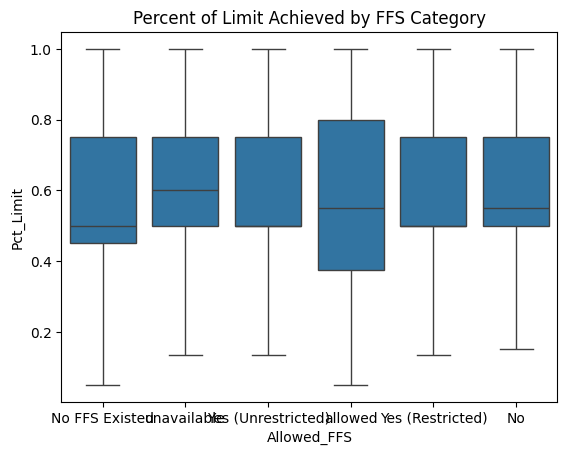

In [64]:
sns.boxplot(
    data=df,
    x="Allowed_FFS",
    y="Pct_Limit",
    showfliers=False
)

plt.title("Percent of Limit Achieved by FFS Category")

plt.show()

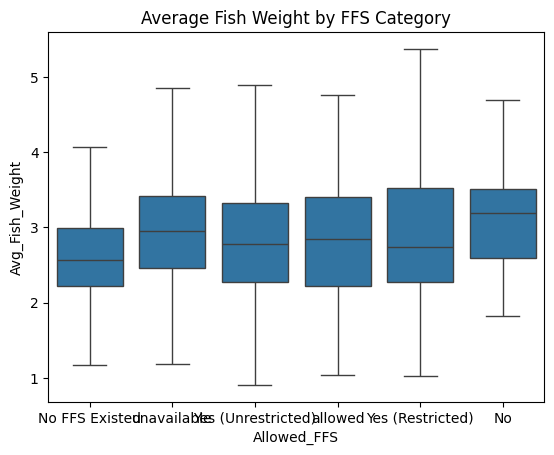

In [65]:
sns.boxplot(
    data=df,
    x="Allowed_FFS",
    y="Avg_Fish_Weight",
    showfliers=False
)

plt.title("Average Fish Weight by FFS Category")

plt.show()

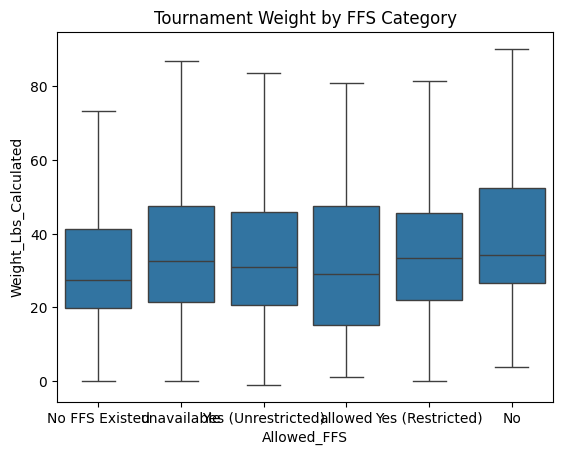

In [66]:
sns.boxplot(
    data=df,
    x="Allowed_FFS",
    y="Weight_Lbs_Calculated",
    showfliers=False
)

plt.title("Tournament Weight by FFS Category")

plt.show()

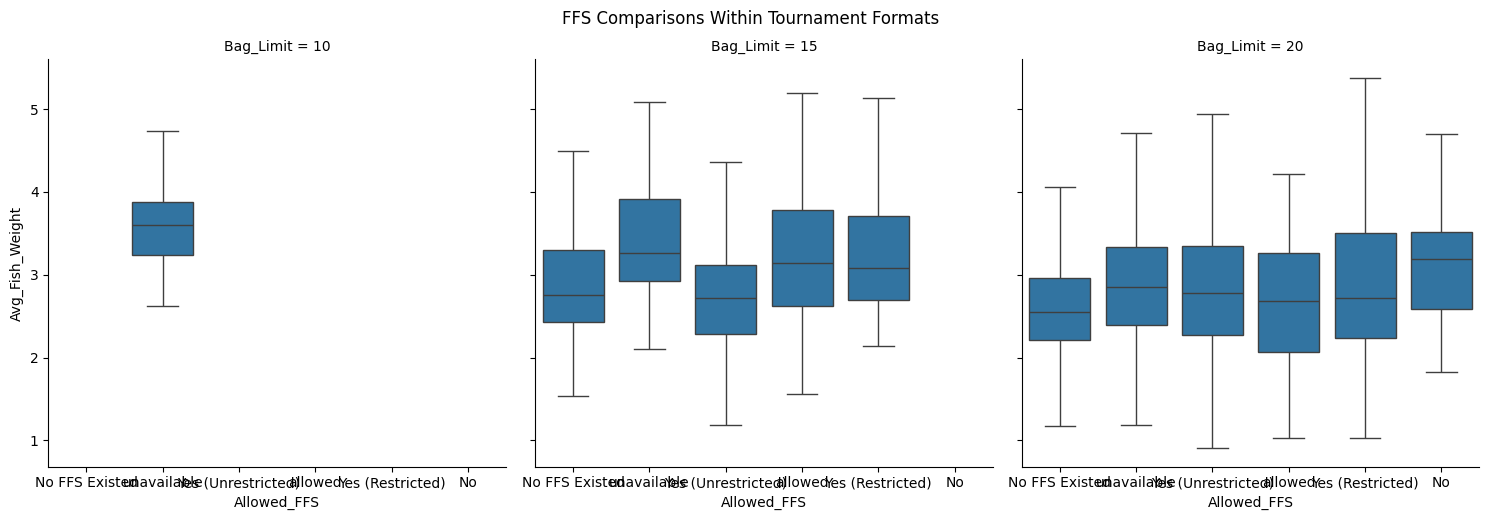

In [67]:
g = sns.catplot(
    data=df,
    x="Allowed_FFS",
    y="Avg_Fish_Weight",
    col="Bag_Limit",
    kind="box",
    showfliers=False,
    height=5,
    aspect=1
)

g.fig.suptitle(
    "FFS Comparisons Within Tournament Formats",
    y=1.03
)

plt.show()


# 9. Fishery-Specific Analysis

The impact of FFS is unlikely to be uniform across bass fisheries.

Clear-water systems with abundant suspended fish may respond differently than shallow vegetated systems.

This section investigates fishery-specific patterns.

### Top Fisheries

In [68]:
top_waterbodies = (
    df["Waterbody"]
      .value_counts()
      .head(10)
      .index
)

### Trends Through Time

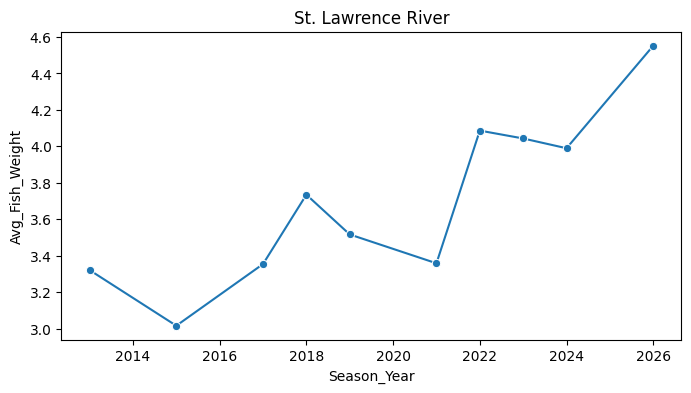

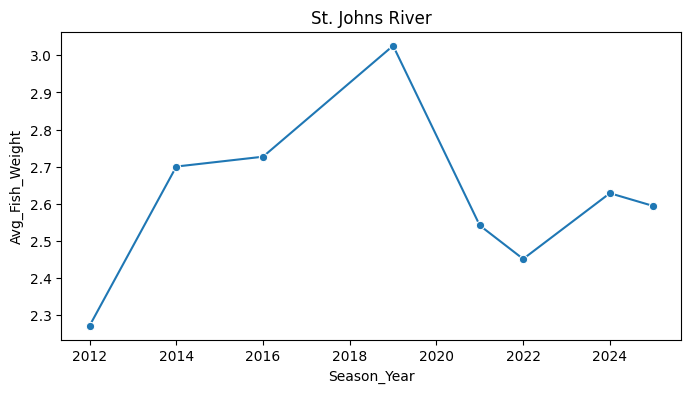

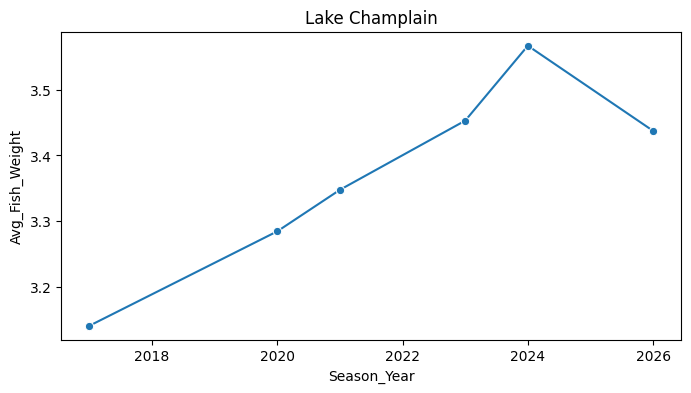

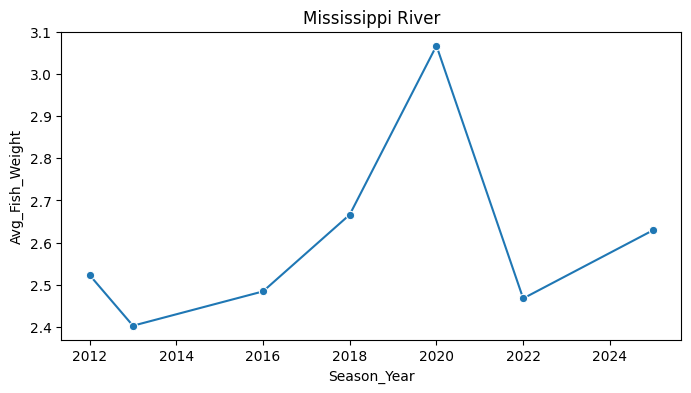

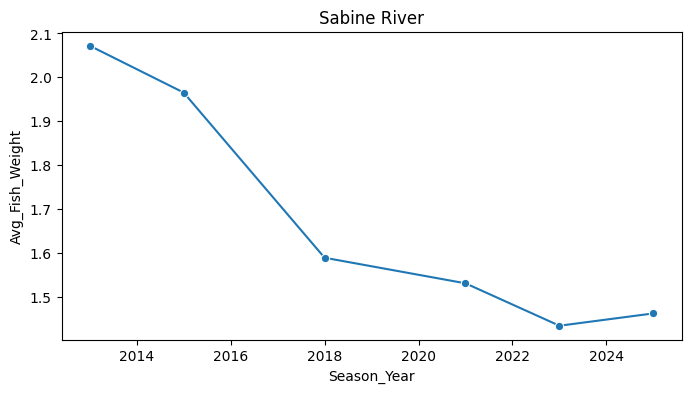

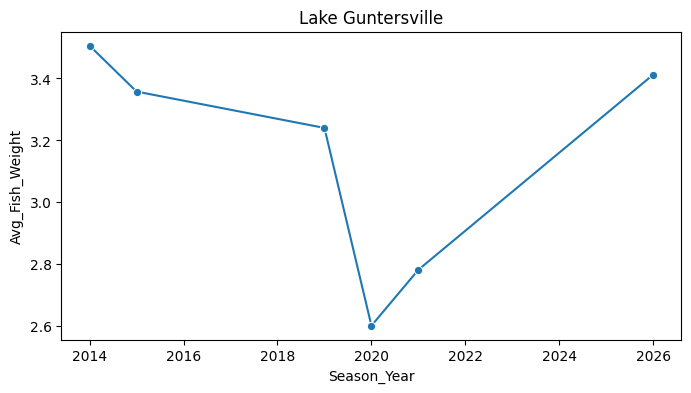

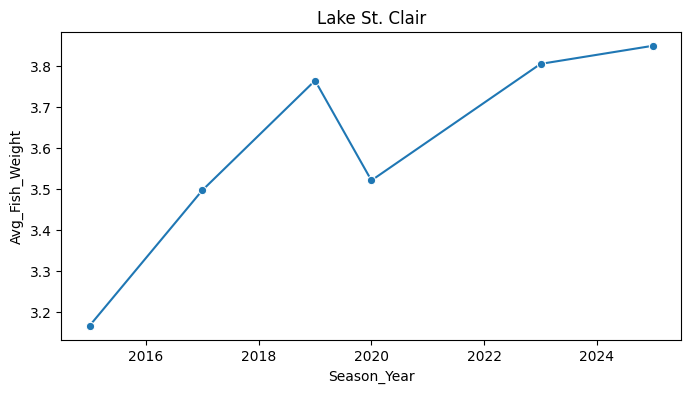

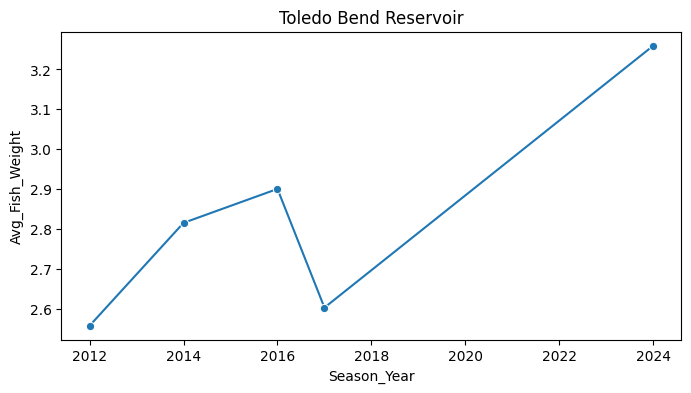

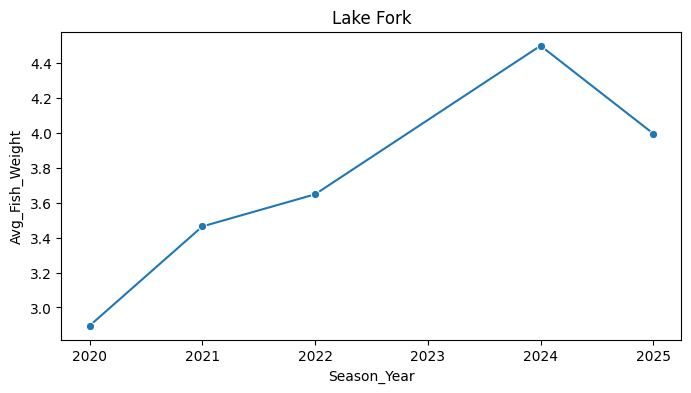

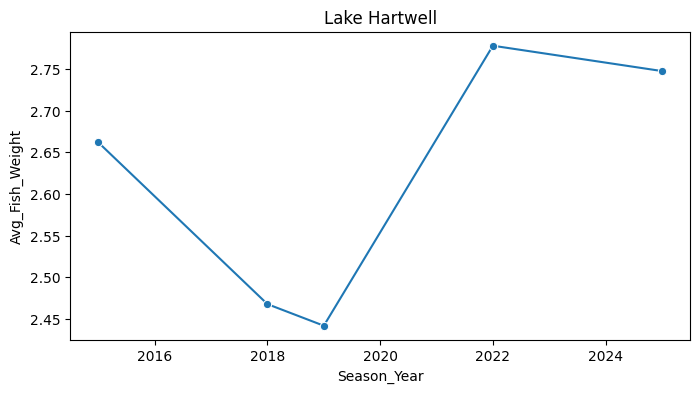

In [69]:
for wb in top_waterbodies:

    subset = df[df["Waterbody"] == wb]

    annual = (
        subset.groupby("Season_Year")
              ["Avg_Fish_Weight"]
              .mean()
              .reset_index()
    )

    plt.figure(figsize=(8,4))

    sns.lineplot(
        data=annual,
        x="Season_Year",
        y="Avg_Fish_Weight",
        marker="o"
    )

    plt.title(wb)

    plt.show()

### Fishery-Specific FFS Effects

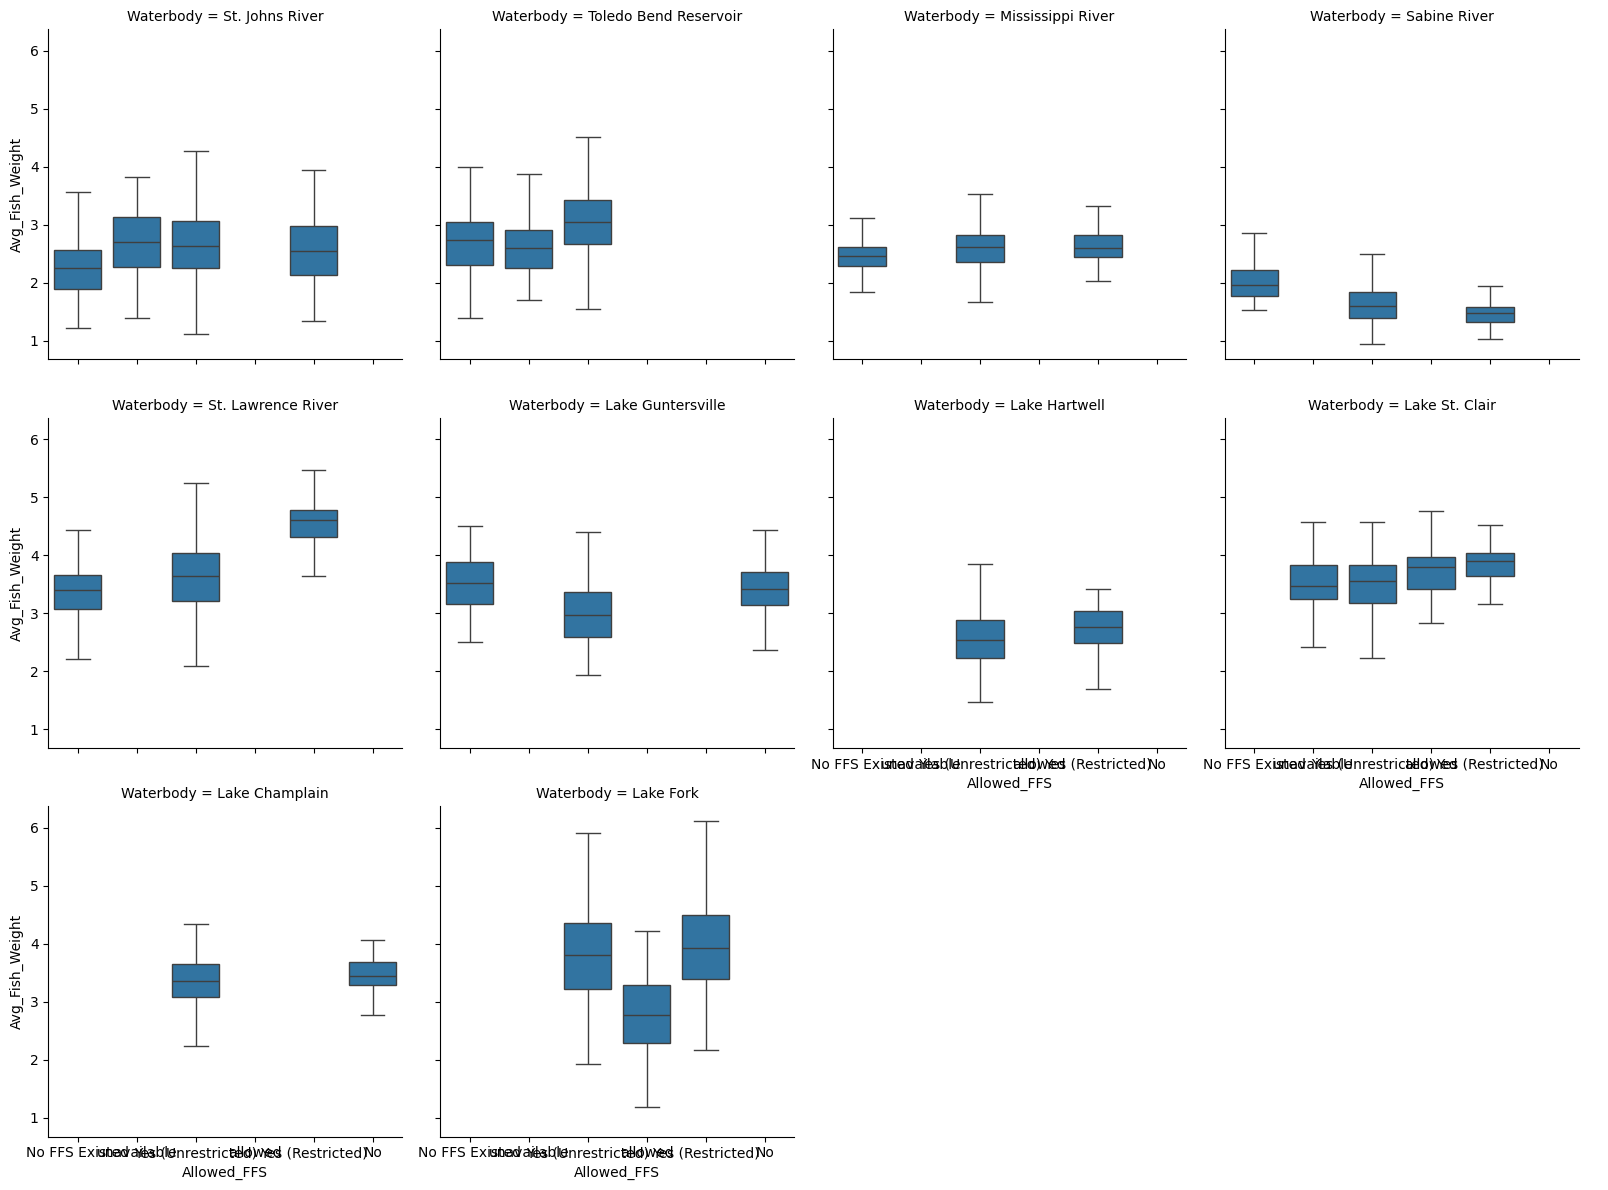

In [70]:
g = sns.catplot(
    data=df[df["Waterbody"].isin(top_waterbodies)],
    x="Allowed_FFS",
    y="Avg_Fish_Weight",
    col="Waterbody",
    col_wrap=4,
    kind="box",
    showfliers=False,
    height=4
)

plt.show()

# 10. Statistical Modeling

The goal of statistical modeling is to determine whether associations between FFS availability and tournament outcomes persist after accounting for tournament structure, time, and fishery differences.

### Model 1: Naive Model

In [71]:
model1 = smf.ols(
    "Avg_Fish_Weight ~ C(Allowed_FFS)",
    data=df
).fit()

print(model1.summary())

NameError: name 'smf' is not defined

### Model 2: Tournament Structure Adjusted

In [72]:
model2 = smf.ols(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    + C(Bag_Limit)
    """,
    data=df
).fit()

print(model2.summary())

NameError: name 'smf' is not defined

### Model 3: Full Fixed Effects Model

In [73]:
model3 = smf.ols(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    + C(Bag_Limit)
    + C(Waterbody)
    + Season_Year
    """,
    data=df
).fit()

print(model3.summary())


NameError: name 'smf' is not defined

### Model 4: Mixed Effects Model

In [74]:
model4 = mixedlm(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    + C(Bag_Limit)
    + Season_Year
    """,
    groups=df["Waterbody"],
    data=df
)

results4 = model4.fit()

print(results4.summary())

NameError: name 'mixedlm' is not defined

### Model 5: Interaction Model

In [75]:
model5 = smf.ols(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    * C(Waterbody)
    + C(Bag_Limit)
    + Season_Year
    """,
    data=df
).fit()

print(model5.summary())

NameError: name 'smf' is not defined

# 11. Limitations

Several limitations affect interpretation of the results.

- The study is observational.
- FFS availability does not guarantee actual FFS use.
- Fishery health metrics were unavailable.
- Tournament formats varied across events.
- Tournament format was inferred from catch data.
- Other technological advances occurred during the study period.
- Environmental conditions were not included.

Consequently, results should be interpreted as associations rather than causal effects.

# 12. Conclusions

This analysis evaluated relationships between forward-facing sonar availability and Bassmaster Elite tournament outcomes from 2012–2026.

A key finding of the exploratory analysis was that tournament structure strongly influences catch statistics. Average fish weight differed considerably among tournament formats, highlighting the importance of accounting for bag limits before evaluating FFS effects.

After controlling for tournament structure, time, and fishery differences, the remaining analyses provide a more defensible assessment of the association between FFS availability and tournament performance.

Future work could incorporate environmental variables, fishery productivity metrics, and angler-level characteristics to further isolate drivers of tournament success.